# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p6"
subproj <- "AVGUSTINOVA_12_13"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "ERBB4"    "RBMS3"    "CADM2"    "NLGN1"    "ANK2"     "FBN2"    
 [7] "SEMA3D"   "KCND2"    "NFIB"     "ADAMTSL1" "MALAT1"   "PDE3A"   
[13] "POSTN"    "RAD51B"   "MIR99AHG"

## Load data

In [8]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- "RNA"

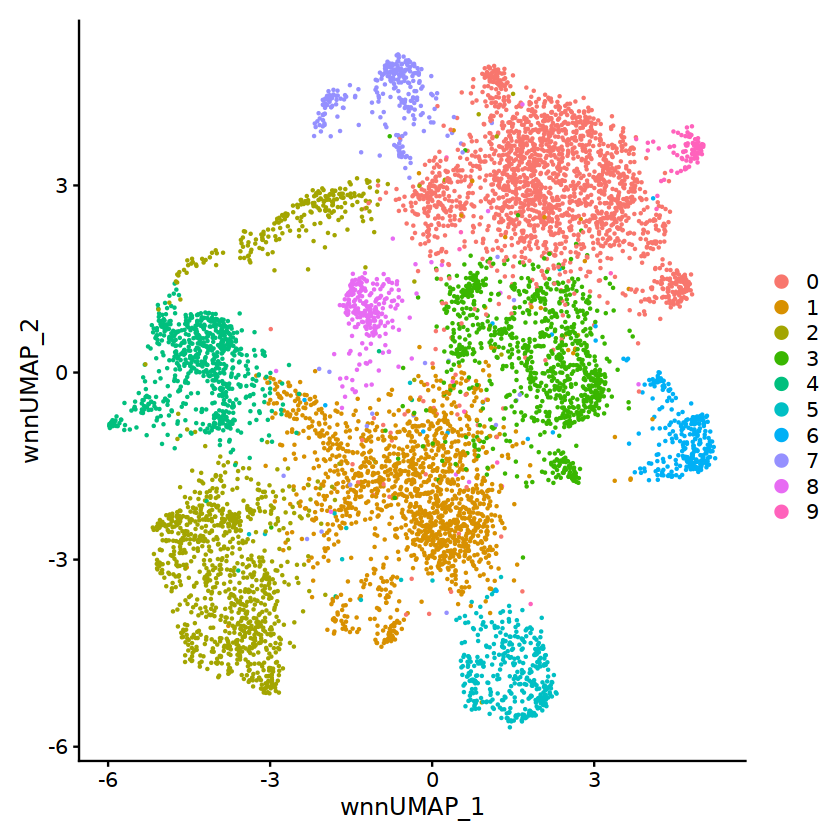

In [9]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

## Re-normalize and cluster

In [10]:
DefaultAssay(seurat_obj) <- assay_ch

In [11]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [12]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [13]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

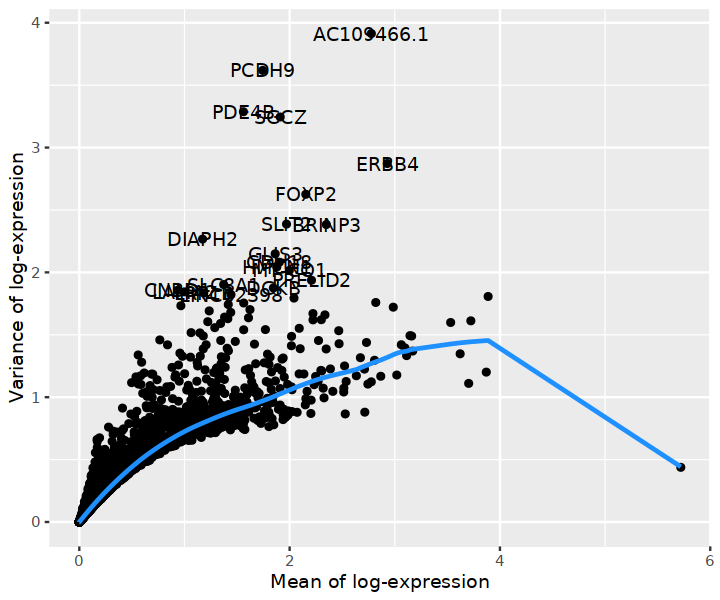

In [14]:
options(repr.plot.width = 6, repr.plot.height = 5)
plt

In [15]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 3928
[1] 3927


In [16]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AL390957.1, STXBP5, KIAA0825, EPHA7, WIF1, AC109466.1, BRINP3, FOXP2, AC011246.1, MCTP2 
	   DGKB, COL5A2, GLIS3, CDH18, PDE4D, GPC3, GRIA2, CTNNA3, PATJ, PRELID2 
	   MMP16, KIF26B, AC078881.1, DOK6, NAALADL2, CCDC85A, LINC02398, SGCZ, GPC6, GALNT13 
Negative:  LRMDA, DOCK4, SLC9A9, ZEB2, SAMSN1, IQGAP2, FRMD4B, DPYD, UTRN, LDLRAD4 
	   PLXDC2, DAPK1, FMNL2, DOCK2, MSR1, FAM49A, KCNMA1, UBE2E2, PTPRE, NPL 
	   MS4A7, RAB31, INPP5D, RUNX1, GAB2, NABP1, SRGN, FYB1, FHIT, CPVL 
PC_ 2 
Positive:  GLIS3, FOXP2, AC109466.1, CCDC85A, KIF26B, FRMD4A, KCNJ3, GALNT13, MIR4527HG, DOK6 
	   CPNE4, GPC3, TPK1, EYA1, ITPR2, TRPS1, LINC01322, AC013287.1, BCHE, LINC02398 
	   AC008415.1, PATJ, ERVMER61-1, RBBP8, LINC00882, SGCZ, LRP1B, AUTS2, KITLG, SLC27A6 
Negative:  PDE4B, DIAPH2, PRR16, EPHA4, LIFR, CEACAM1, PCDH9, HGF, ELMO1, ANK3 
	   LINC02643, PCDH19, KCNE4, RHOBTB1, ELMOD1, SLC4A4, LGR4, SOX6, TIAM1, SORBS1 
	   PRAG1, PEG3, MDM1, GRIK4, T

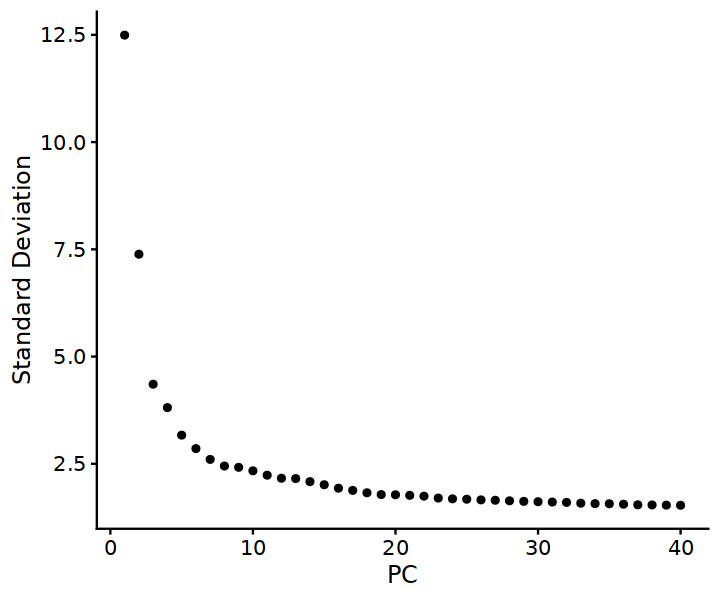

In [17]:
ElbowPlot(seurat_obj, n=40)

In [18]:
dcomp$rna <- 1:15

In [19]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


15:24:21 UMAP embedding parameters a = 0.9922 b = 1.112

15:24:21 Read 7417 rows and found 15 numeric columns

15:24:21 Using Annoy for neighbor search, n_neighbors = 30

15:24:21 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:24:21 Writing NN index file to temp file /scratch_tmp/49729482/Rtmp6l3yrw/file253d27bafa8f4

15:24:21 Searching Annoy index using 1 thread, search_k = 3000

15:24:23 Annoy recall = 99.66%

15:24:24 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:24:24 58 smooth knn distance failures

15:24:26 Initializing from normalized Laplacian + noise (using irlba)

15:24:26 Commencing optimization for 500 epochs, with 300952 positive edges

15:24:48 Optimization

In [20]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [21]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

15:25:09 UMAP embedding parameters a = 0.9922 b = 1.112

15:25:10 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:25:10 57 smooth knn distance failures

15:25:11 Initializing from normalized Laplacian + noise (using irlba)

15:25:11 Commencing optimization for 500 epochs, with 215578 positive edges

15:25:35 Optimization finished



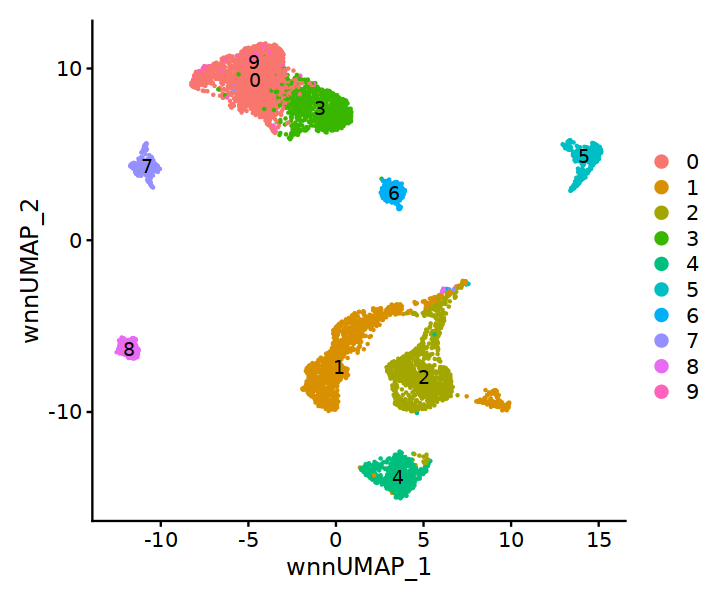

In [22]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

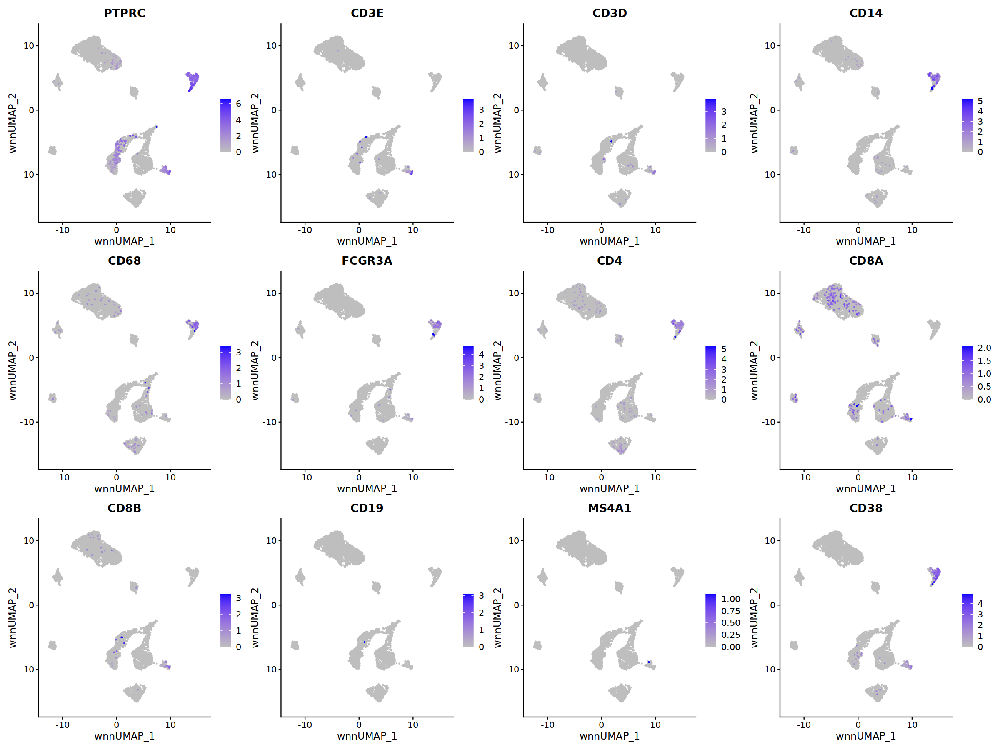

In [23]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

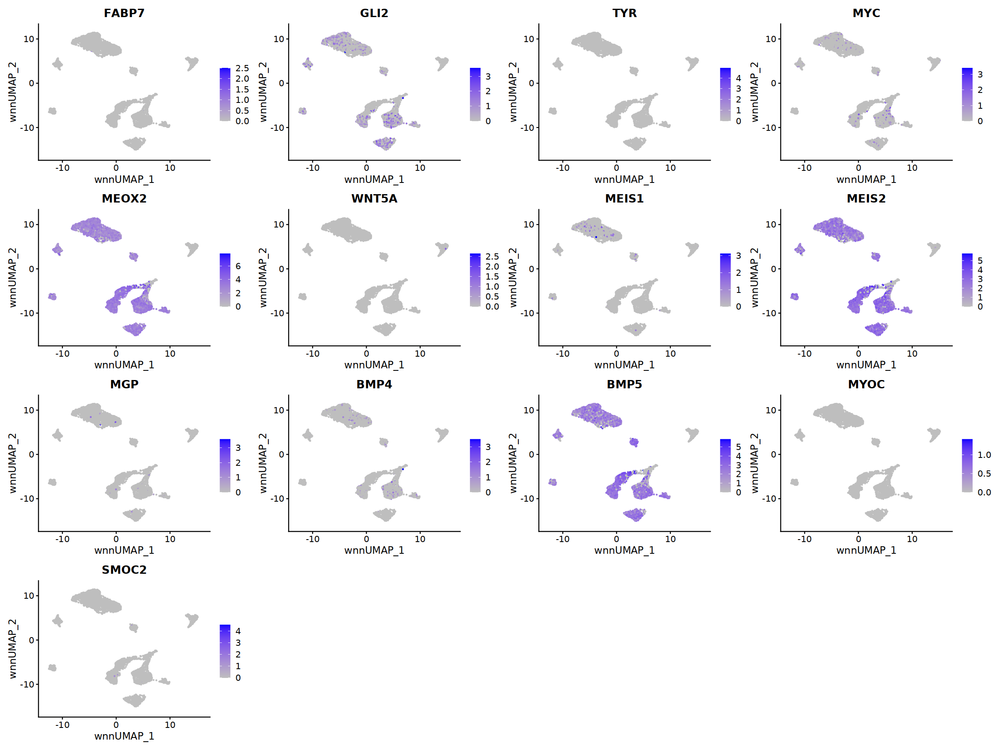

In [24]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

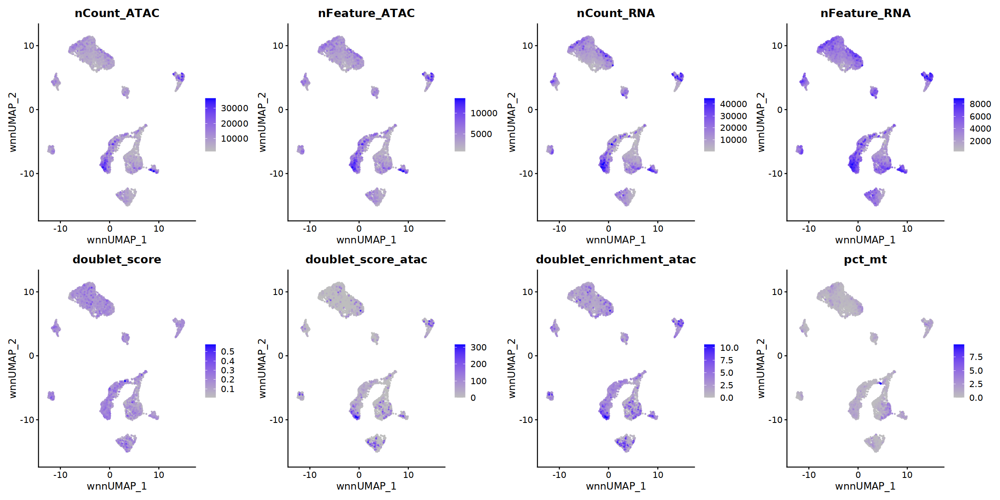

In [25]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

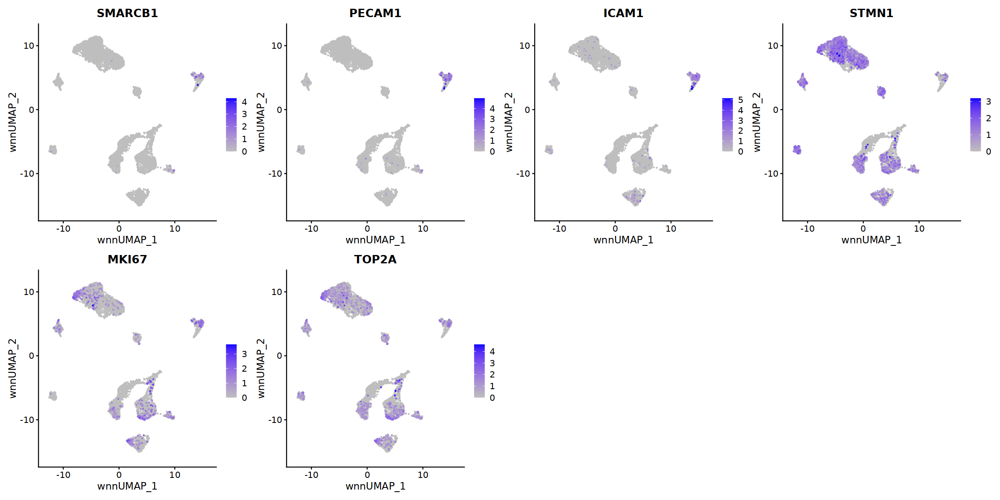

In [26]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

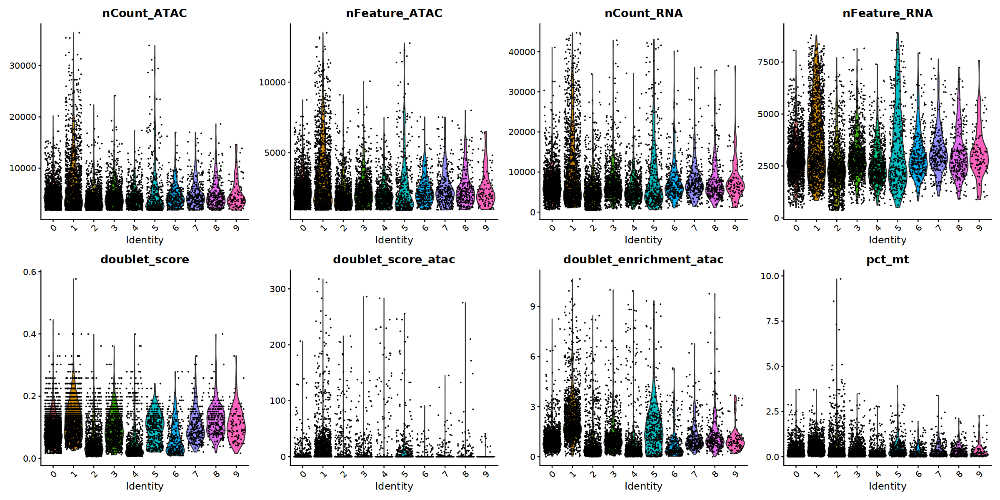

In [27]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

In [28]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7417
Number of edges: 258869

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9762
Number of communities: 9
Elapsed time: 0 seconds


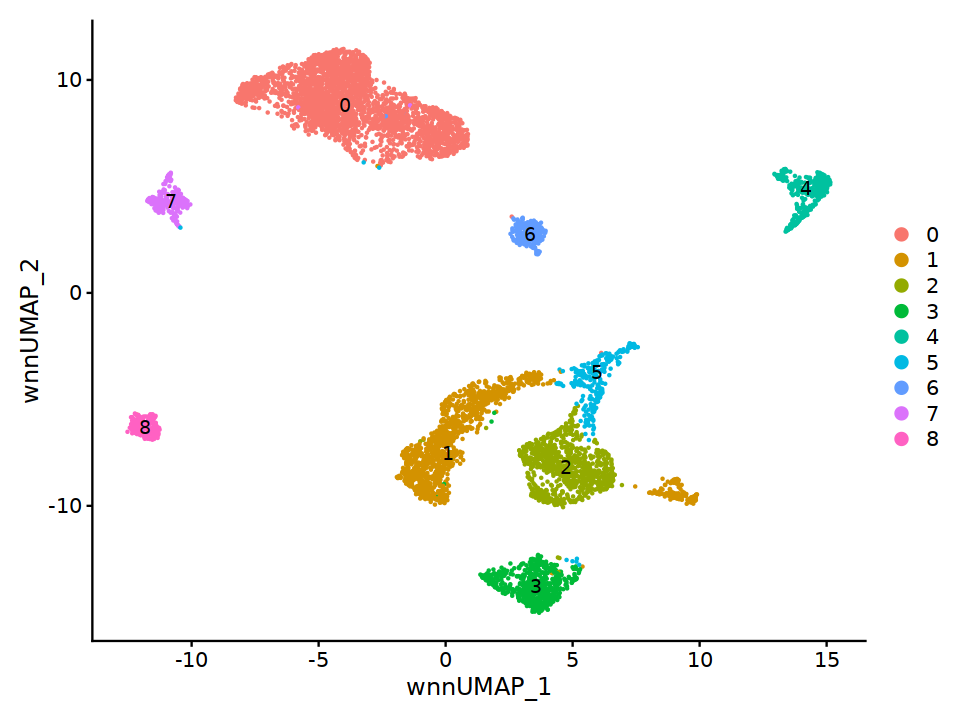

In [29]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

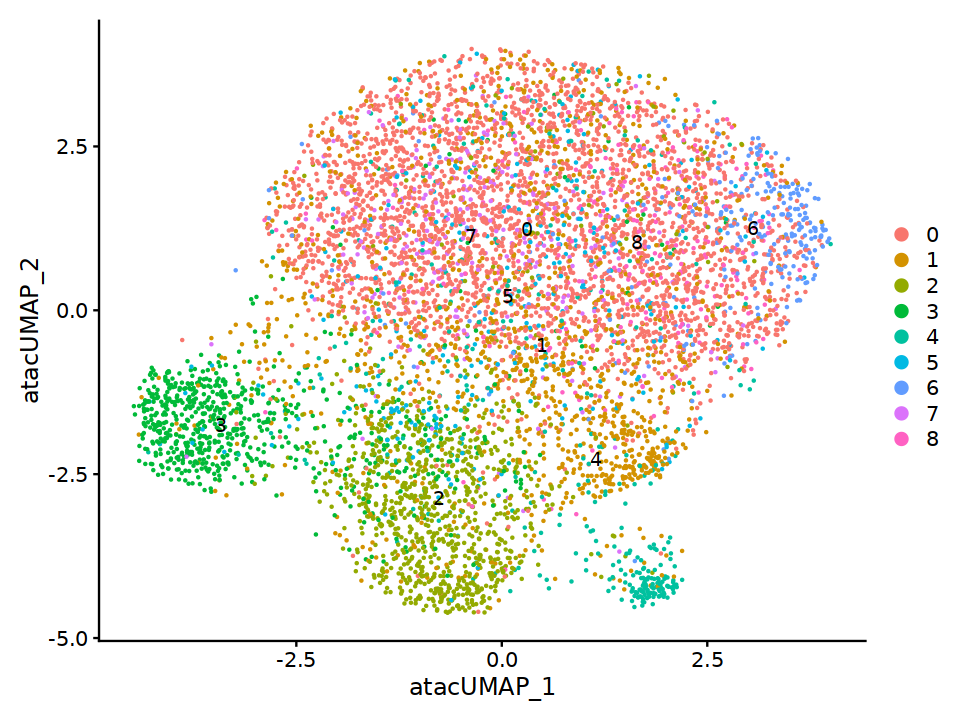

In [30]:
DimPlot(seurat_obj, reduction = "umap.atac", label=T) 

In [31]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



In [32]:
rna.markers %>% 
  dplyr::filter(cluster == "0") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CNBD1,1.540803e-260,1.950016,0.589,0.226,4.774178e-256,0,CNBD1
CNTNAP2,1.078777e-181,1.777239,0.442,0.154,3.342590e-177,0,CNTNAP2
PTPRD,2.456029e-236,1.735777,0.546,0.204,7.610007e-232,0,PTPRD
THSD7B,7.353959e-184,1.696912,0.297,0.058,2.278624e-179,0,THSD7B
PPP3CA,0.000000e+00,1.694762,0.696,0.251,0.000000e+00,0,PPP3CA
CCDC85A,0.000000e+00,1.660567,0.931,0.347,0.000000e+00,0,CCDC85A
SGCZ,0.000000e+00,1.659046,0.848,0.378,0.000000e+00,0,SGCZ
SLC39A8,0.000000e+00,1.644573,0.614,0.167,0.000000e+00,0,SLC39A8
LINC01322,0.000000e+00,1.642193,0.864,0.329,0.000000e+00,0,LINC01322


In [33]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  1,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.2,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1357
Number of edges: 47196

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8879
Number of communities: 3
Elapsed time: 0 seconds


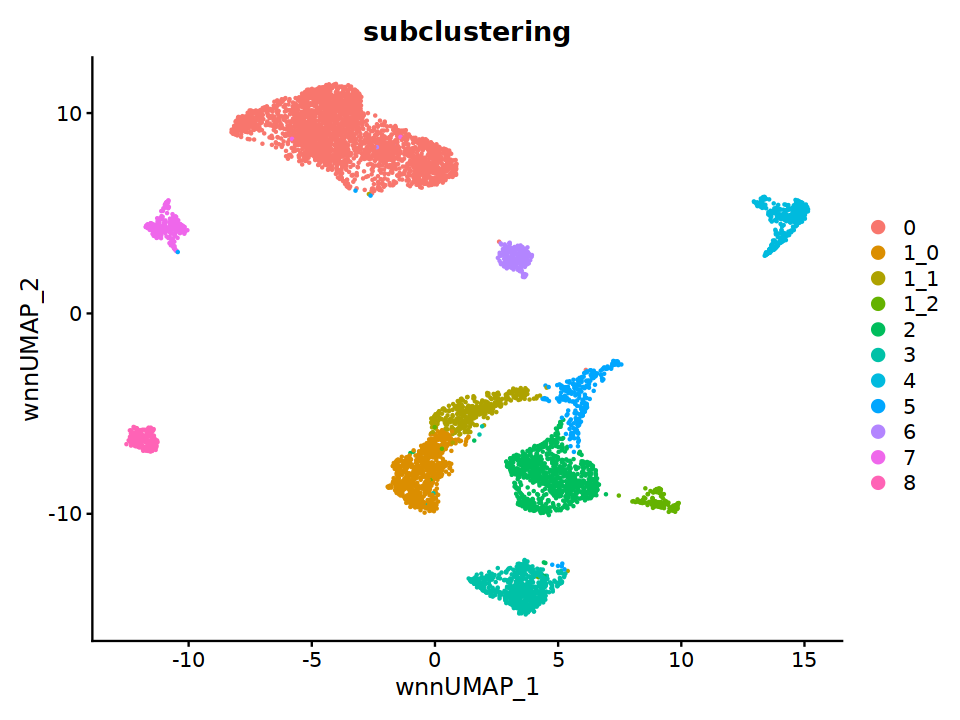

In [34]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering", label = F, label.size = 6)

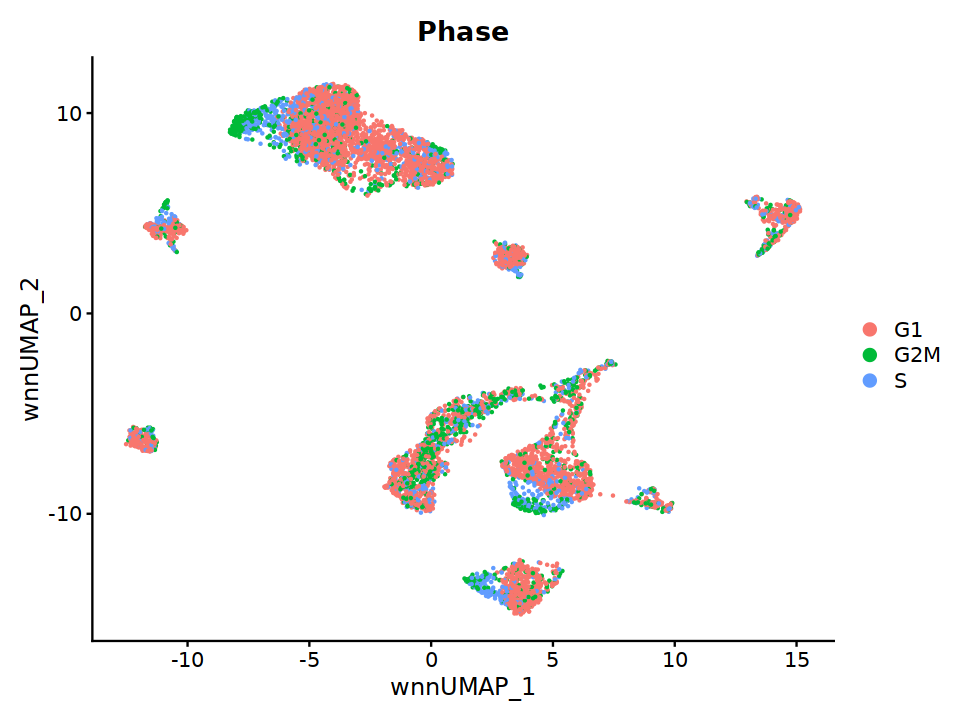

In [35]:
DimPlot(seurat_obj, reduction = "wnn.umap", group.by="Phase")

In [36]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data[["subclustering"]])

In [37]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  5,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.2,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 298
Number of edges: 9498

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8559
Number of communities: 2
Elapsed time: 0 seconds


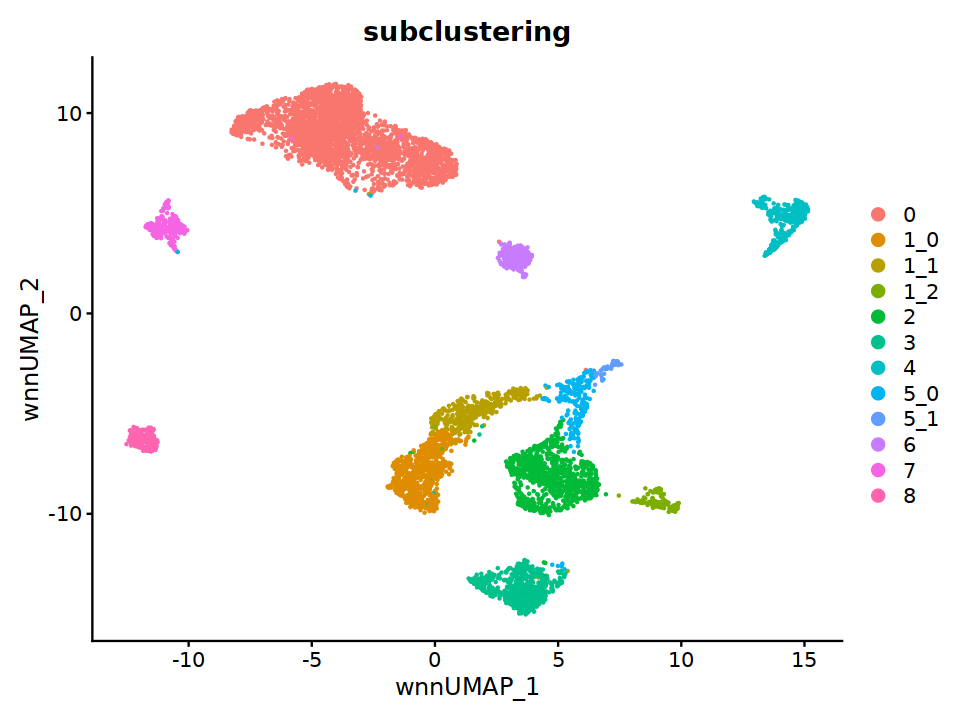

In [38]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering", label = F, label.size = 6)

In [39]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data[["subclustering"]])

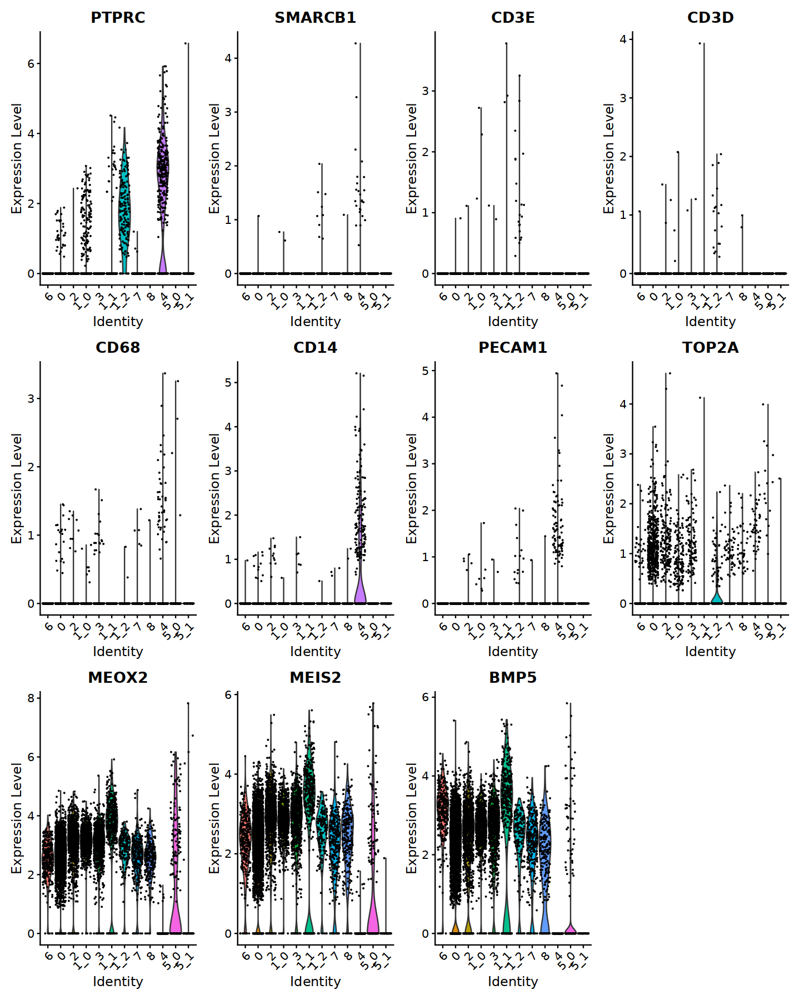

In [40]:
options(repr.plot.width = 12, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PTPRC", "SMARCB1", "CD3E", "CD3D",
                              "CD68", "CD14", "PECAM1", "TOP2A",
                              "MEOX2", "MEIS2", "BMP5"), 
        ncol = 4)

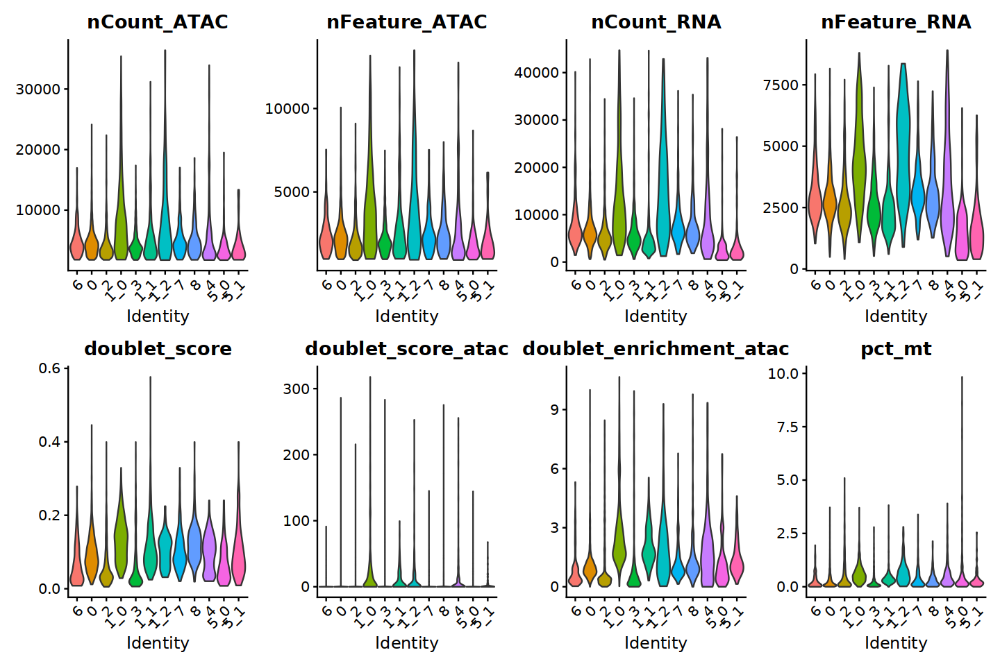

In [41]:
options(repr.plot.width = 12, repr.plot.height = 8)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

In [42]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 6

Calculating cluster 0

Calculating cluster 2

Calculating cluster 1_0

Calculating cluster 3

Calculating cluster 1_1

Calculating cluster 1_2

Calculating cluster 7

Calculating cluster 8

Calculating cluster 4

Calculating cluster 5_0

Calculating cluster 5_1



In [43]:
rna.markers %>% 
  dplyr::filter(cluster == "5_1") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
MALAT12,6.056494e-35,3.8262296,0.908,1.000,1.876605e-30,5_1,MALAT1
RPS3A2,1.976627e-17,2.6895772,0.034,0.558,6.124577e-13,5_1,RPS3A
CADM24,9.898719e-07,2.4435756,0.345,0.929,3.067118e-02,5_1,CADM2
NLGN14,1.111519e-10,2.3221860,0.276,0.934,3.444042e-06,5_1,NLGN1
KCND24,6.885619e-30,2.2600609,0.115,0.906,2.133509e-25,5_1,KCND2
ADCY93,2.340697e-10,2.2266055,0.011,0.351,7.252651e-06,5_1,ADCY9
GPSM22,1.369410e-09,1.9745705,0.011,0.329,4.243116e-05,5_1,GPSM2
RPS63,3.262541e-16,1.9724002,0.023,0.511,1.010898e-11,5_1,RPS6
MEST3,2.928283e-15,1.9176448,0.011,0.469,9.073286e-11,5_1,MEST


## Filter cells

Low quality cells (1_0, 1_1, 5_0, 5_1) and doublets (1_2)

In [44]:
seurat_obj <- subset(seurat_obj, idents = c("1_0", "1_1", "1_2", "5_0", "5_1"), invert = TRUE)

In [45]:
DefaultAssay(seurat_obj) <- assay_ch

In [46]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [47]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [48]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [49]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

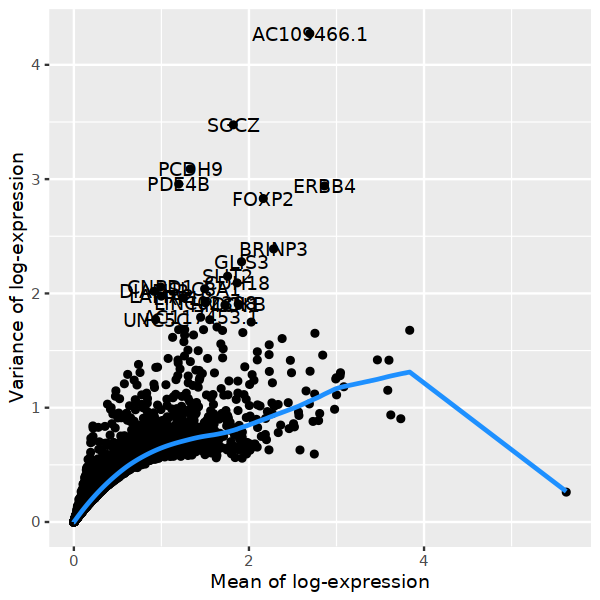

In [50]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [51]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AL390957.1, STXBP5, KIAA0825, ERBB4, WIF1, EPHA7, BRINP3, AC011246.1, MCTP2, AC109466.1 
	   FOXP2, DGKB, GPC3, PATJ, GLIS3, GRIA2, COL5A2, CDH18, CTNNA3, KIF26B 
	   PDE4D, CCDC85A, DOK6, AC078881.1, GPC6, LINC02398, GALNT13, KCNJ3, MMP16, PRELID2 
Negative:  LRMDA, DOCK4, ZEB2, UTRN, SLC9A9, DPYD, SAMSN1, PTPRC, IQGAP2, DOCK2 
	   FRMD4B, PLXDC2, LDLRAD4, FMNL2, CELF2, DAPK1, MSR1, FAM49A, KCNMA1, DOCK8 
	   UBE2E2, RUNX1, PTPRE, FYB1, INPP5D, RAB31, MS4A7, ARHGAP15, NPL, GAB2 
PC_ 2 
Positive:  AC109466.1, FOXP2, GLIS3, KIF26B, CCDC85A, ITPR2, FRMD4A, GALNT13, DOK6, KCNJ3 
	   GPC3, TPK1, TRPS1, LINC01322, CPNE4, EYA1, LINC02398, SGCZ, AC008415.1, AC013287.1 
	   BCHE, PATJ, ERVMER61-1, LINC00882, LRP1B, DST, RBBP8, AUTS2, CTNNA3, STXBP5 
Negative:  DIAPH2, PDE4B, PRR16, EPHA4, LIFR, CEACAM1, HGF, ANK3, LINC02643, PCDH9 
	   ELMO1, PCDH19, ELMOD1, KCNE4, RHOBTB1, TIAM1, SLC4A4, SOX6, SORBS1, LGR4 
	   PRAG1, SHC4, MDM1, GRIK4, TTC

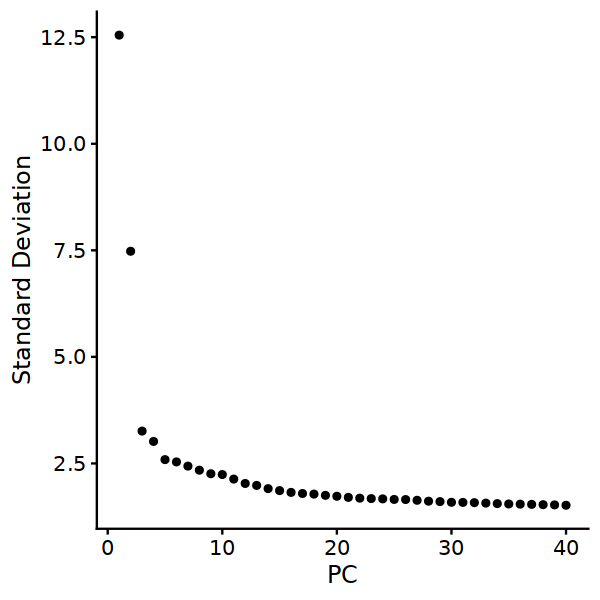

In [52]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [53]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [54]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



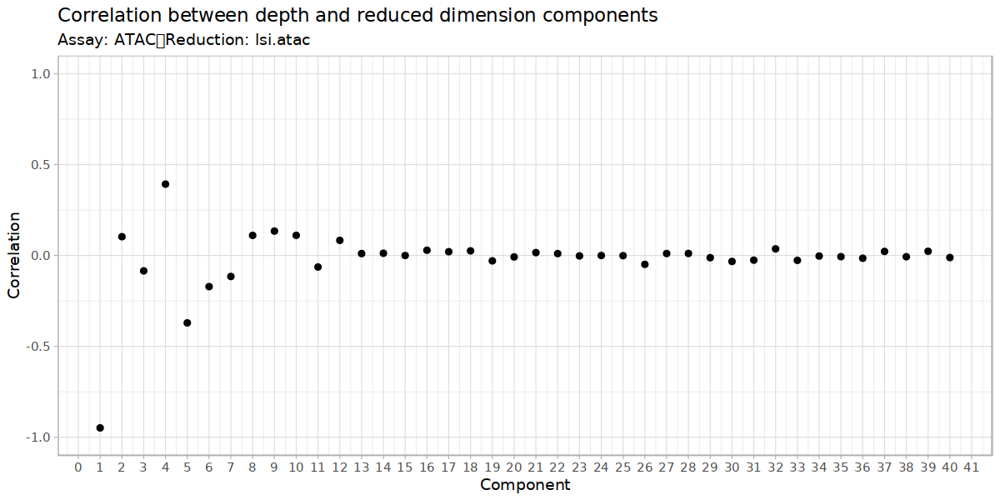

In [55]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

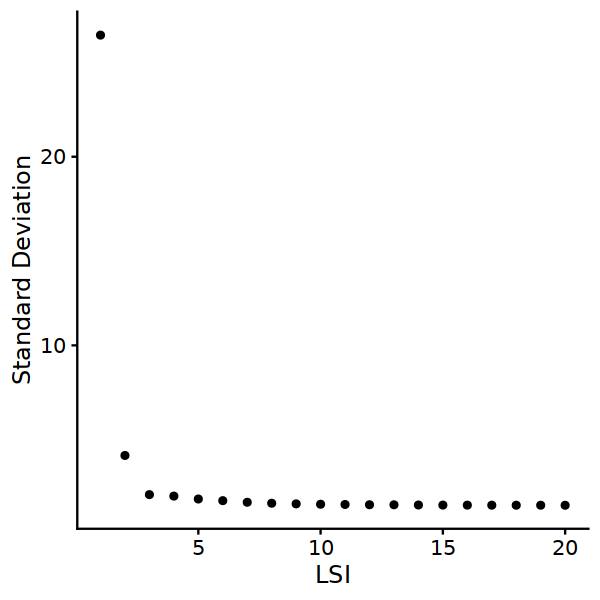

In [56]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [57]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [58]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

15:33:43 UMAP embedding parameters a = 0.115 b = 1.929

15:33:44 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:33:46 Initializing from normalized Laplacian + noise (using irlba)

15:33:46 Commencing optimization for 500 epochs, with 168404 positive edges

15:34:04 Optimization finished



In [59]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5762
Number of edges: 198736

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9783
Number of communities: 8
Elapsed time: 0 seconds


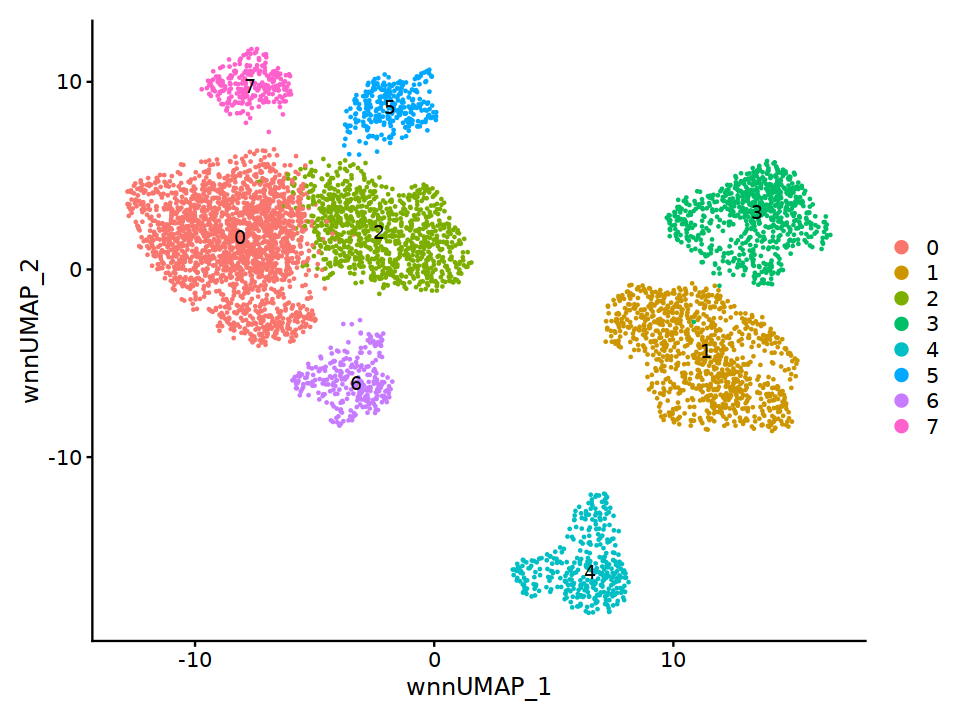

In [60]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [61]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



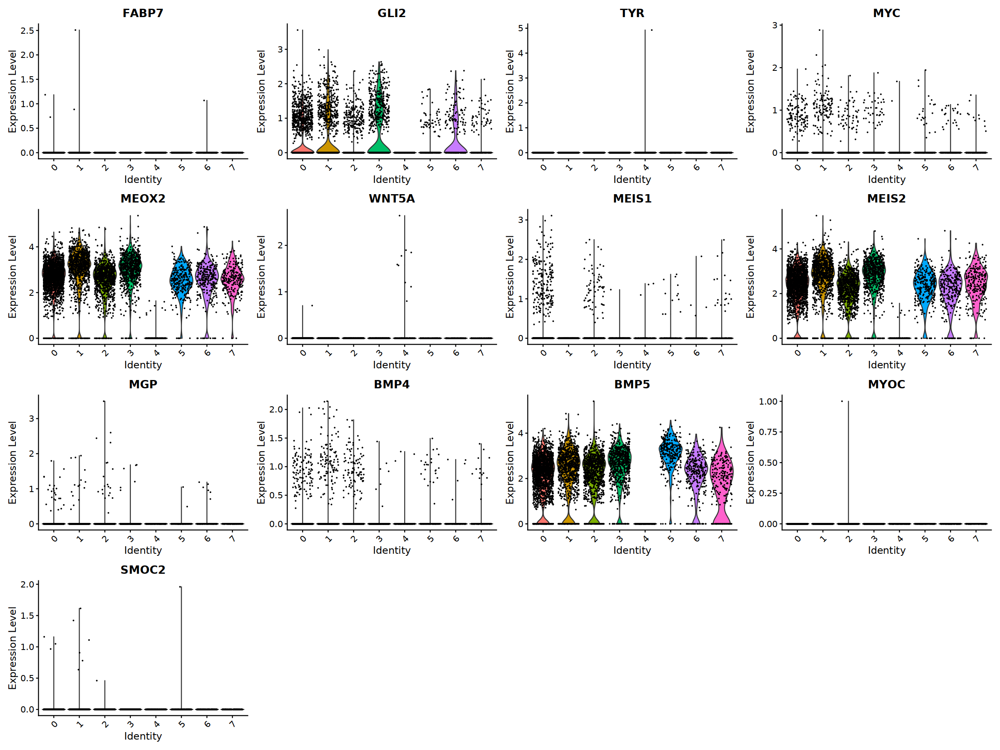

In [62]:
options(repr.plot.width = 20, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

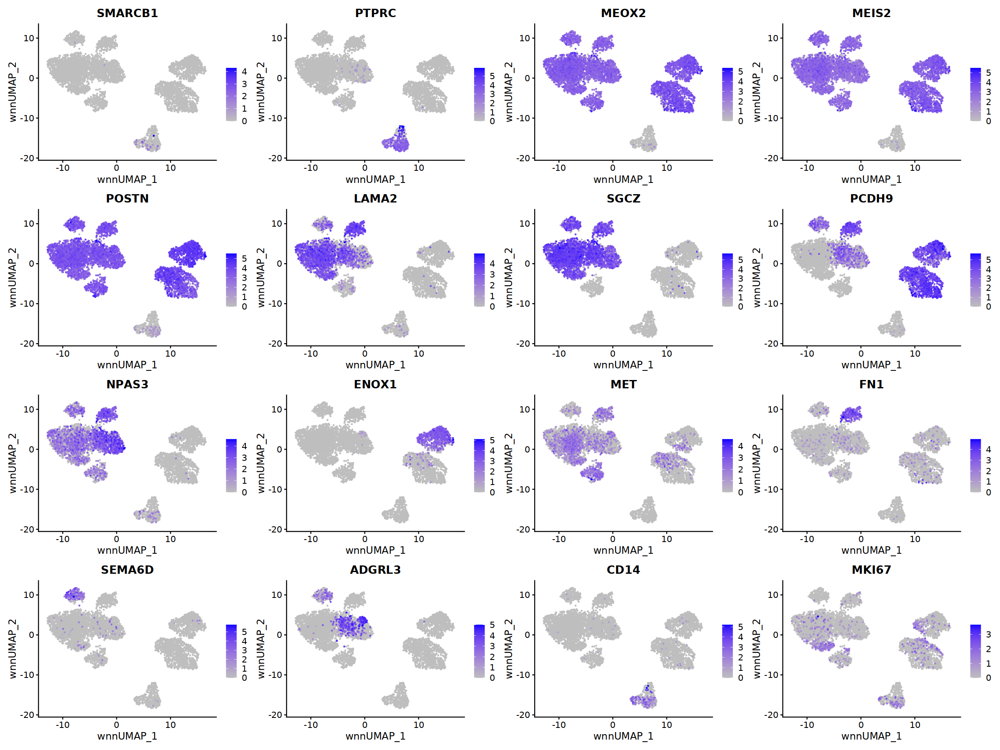

In [63]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC", "MEOX2", "MEIS2","POSTN", "LAMA2", 
                              "SGCZ", "PCDH9", "NPAS3", "ENOX1", "MET",
                             "FN1", "SEMA6D", "ADGRL3", "CD14", "MKI67"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

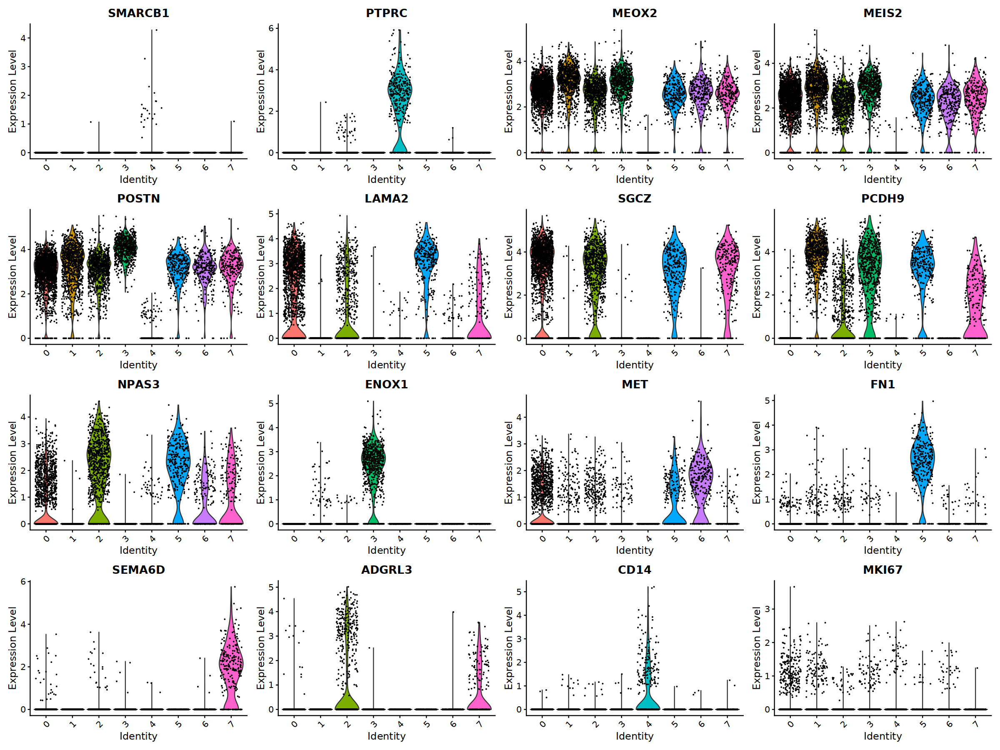

In [64]:
VlnPlot(seurat_obj, feature=vars2plot)

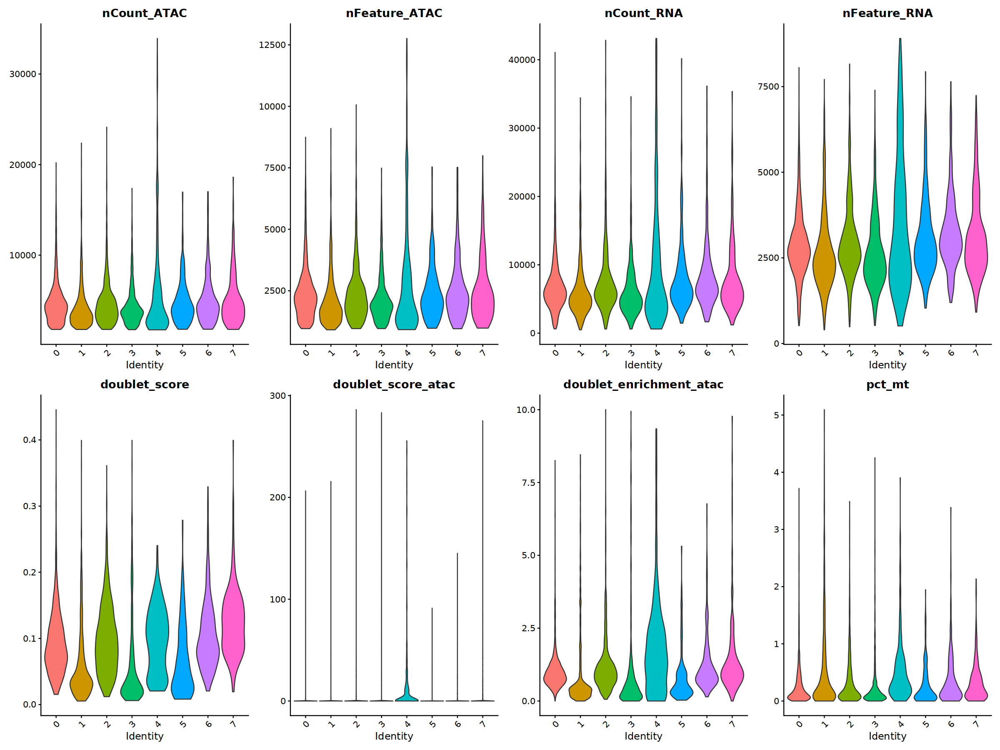

In [65]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

In [66]:
rna.markers %>% 
  dplyr::filter(cluster == "1") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
NAALADL2-AS2,0.000000e+00,2.884930,0.558,0.057,0.000000e+00,1,NAALADL2-AS2
INPP4B,5.766668e-213,2.766694,0.529,0.119,1.740496e-208,1,INPP4B
PCDH9,0.000000e+00,2.585494,0.965,0.295,0.000000e+00,1,PCDH9
LIFR,0.000000e+00,2.467237,0.868,0.130,0.000000e+00,1,LIFR
PDE4B,0.000000e+00,2.400315,0.979,0.219,0.000000e+00,1,PDE4B
PRR16,0.000000e+00,2.357676,0.832,0.118,0.000000e+00,1,PRR16
CHN1,0.000000e+00,2.330764,0.604,0.086,0.000000e+00,1,CHN1
DIAPH2,0.000000e+00,2.316808,0.949,0.186,0.000000e+00,1,DIAPH2
EPHA4,0.000000e+00,2.186287,0.823,0.124,0.000000e+00,1,EPHA4


### Rename

In [67]:
rename_clusters <- c("0"="Tumor SGCZ", "1"="Tumor PCDH9",
                     "2"="Tumor ADGRL3", "3"="Tumor ENOX1",
                     "4"="Monocytes-Macrophages","5"="Tumor FN1",
                     "6"="Tumor MET", "7"="Tumor SEMA6D")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [68]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [69]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [70]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [71]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [72]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune



In [73]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

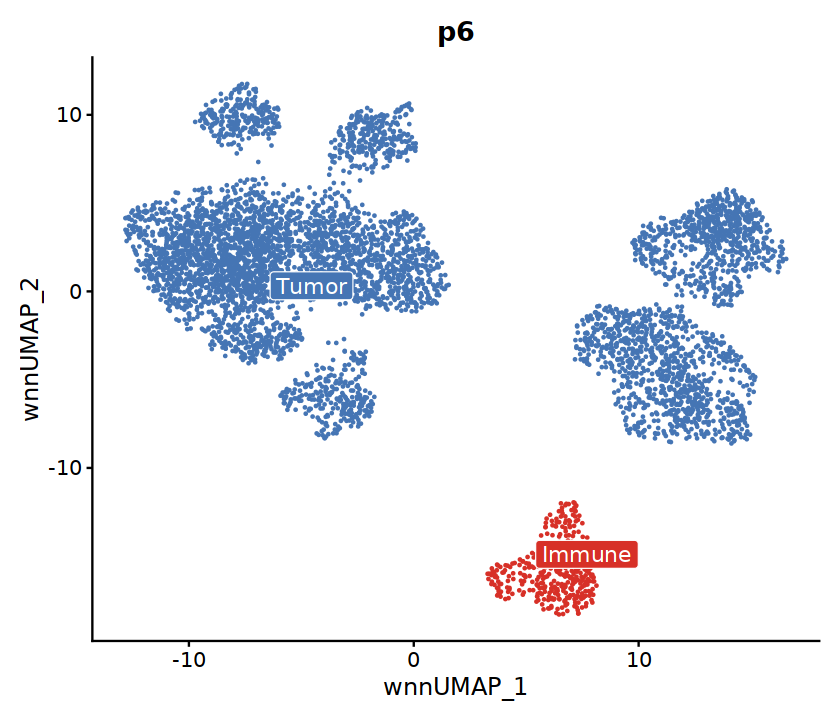

In [74]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [75]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [76]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [79]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

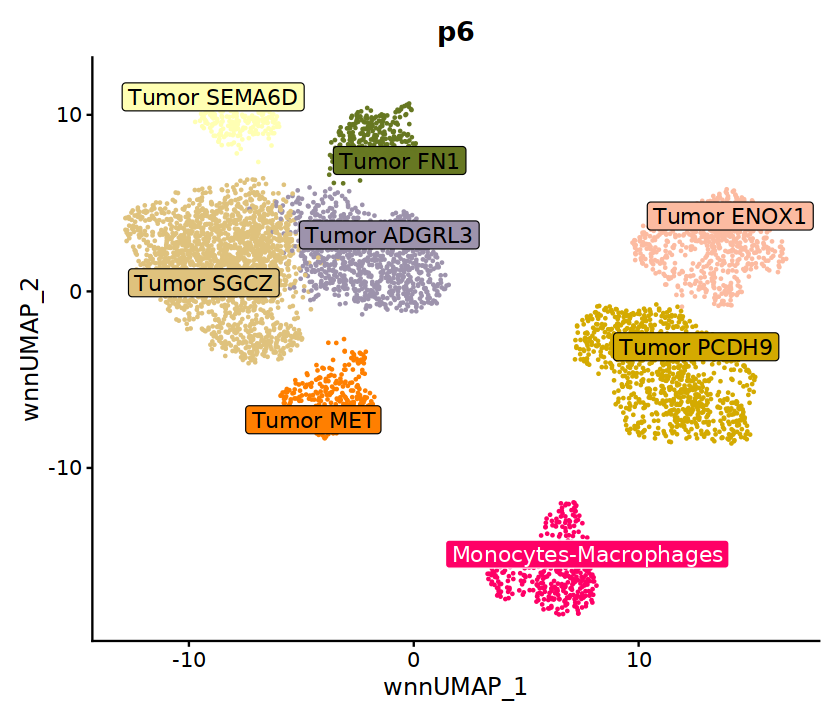

In [80]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [81]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

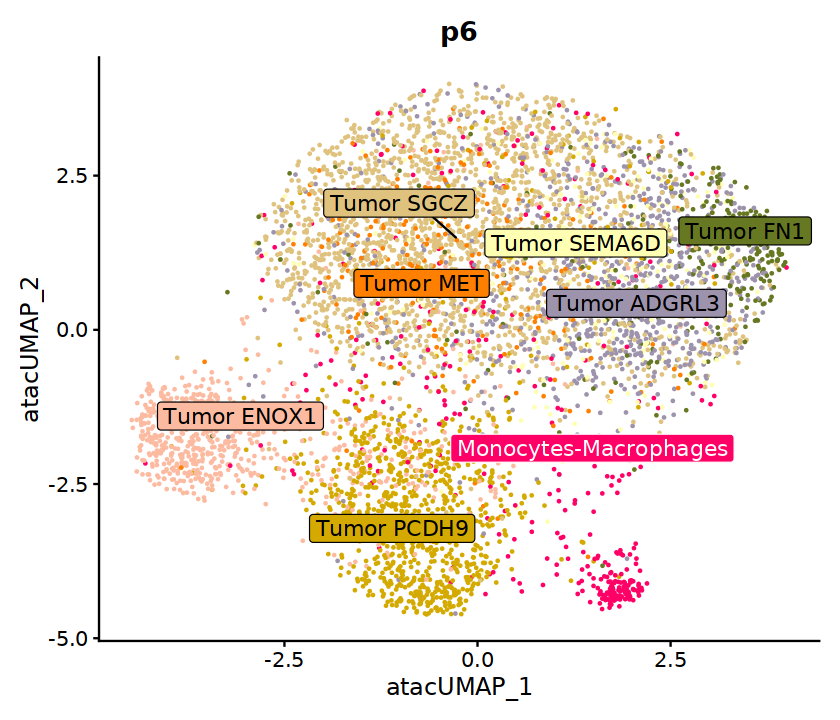

In [82]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [83]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

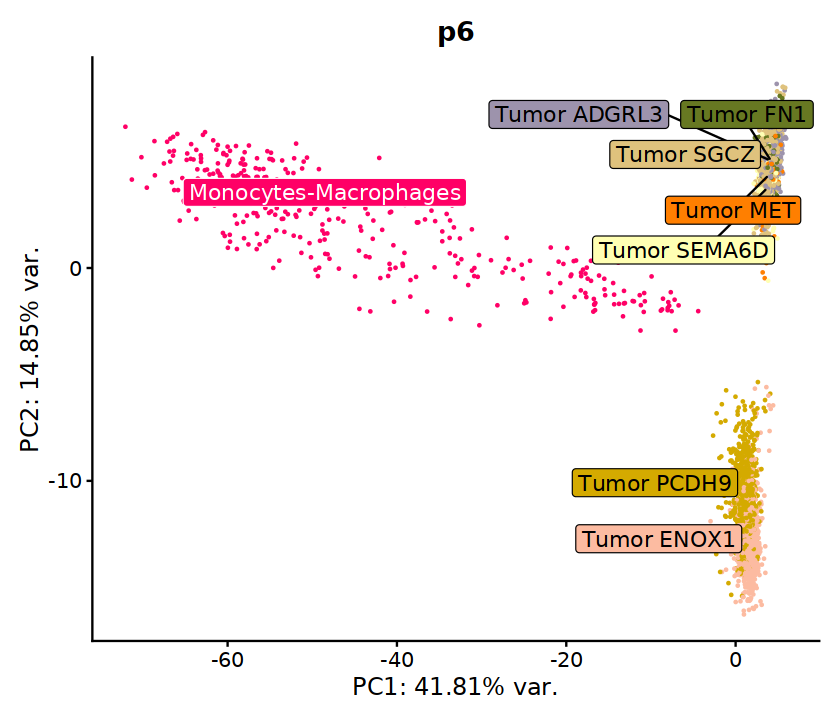

In [84]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

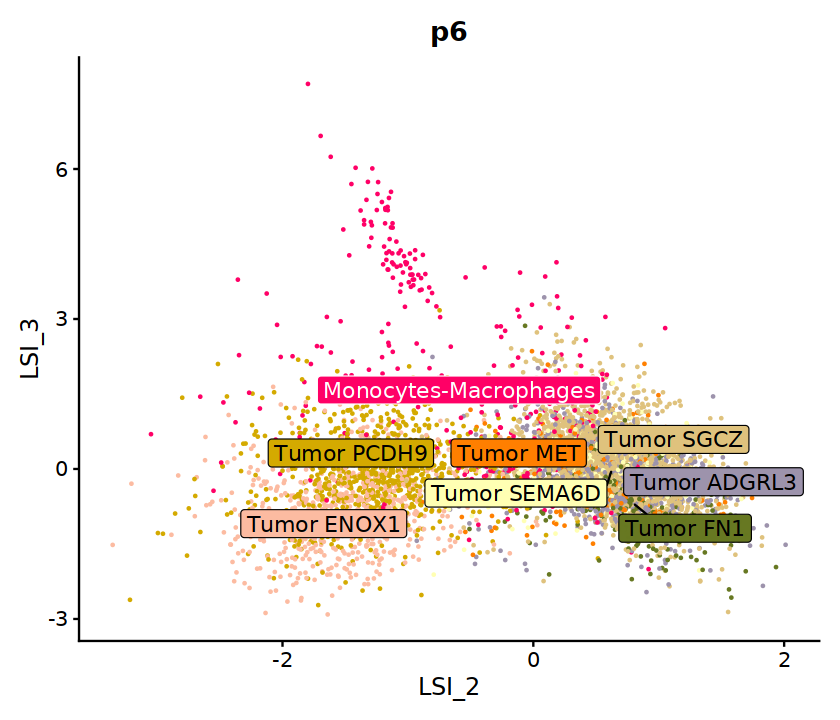

In [85]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

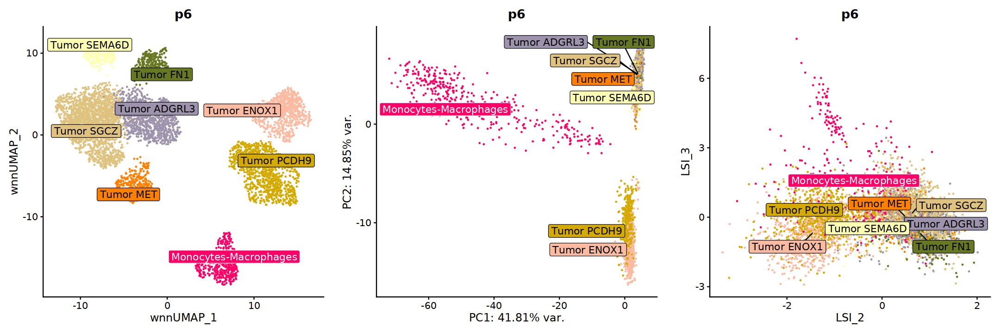

In [86]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [87]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [88]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEOX2", "MEIS2", "POSTN","GPC3"), markers) ## common markers to all clusters

In [89]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

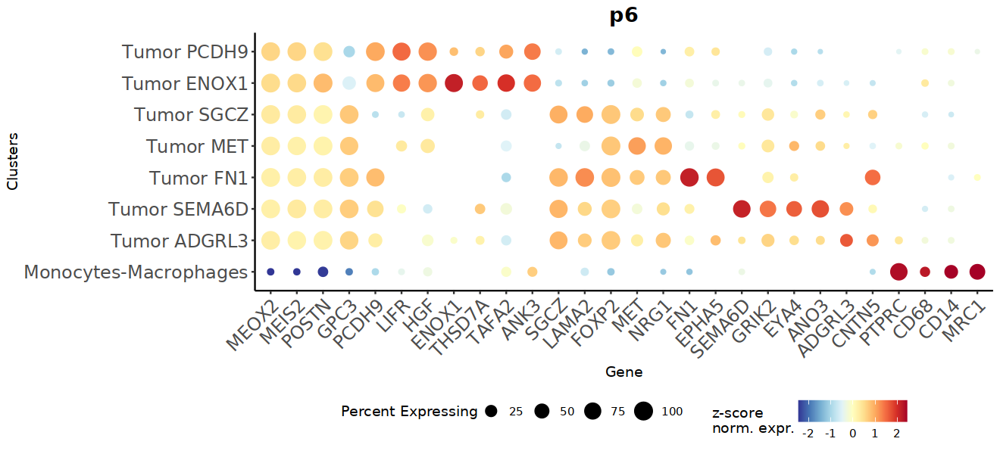

In [90]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

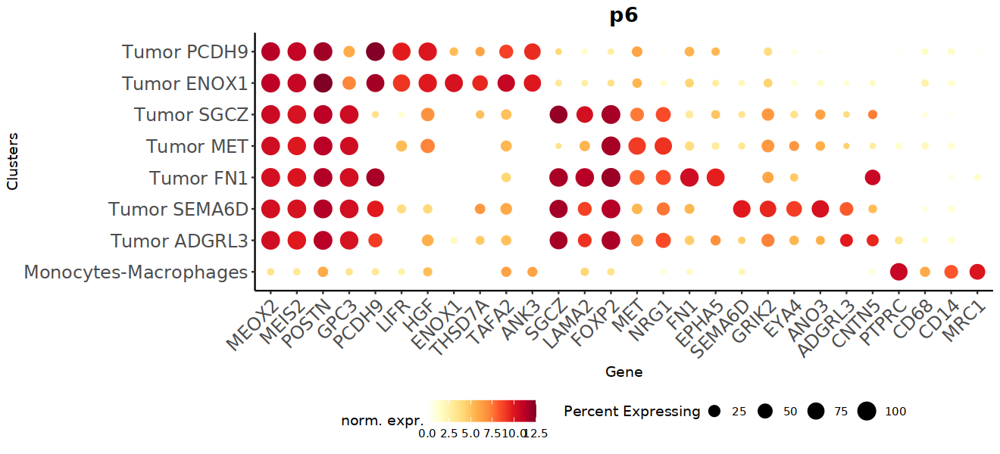

In [91]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [92]:
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [93]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [94]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [95]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [96]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    